# 05 - Backtest Engine: Costs, Sizing, Risk Limits

Turns notebook 04's signals into an actual P&L series: correct execution timing, transaction costs, volatility-targeted and Kelly position sizing, and a portfolio-level gross exposure cap across both pairs. Still training period only - the holdout stays untouched until notebook 06.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "../data"

fx_sig = pd.read_parquet(f"{DATA_DIR}/signals_fx.parquet")
comm_sig = pd.read_parquet(f"{DATA_DIR}/signals_comm.parquet")

print("FX:", fx_sig.index.min().date(), "->", fx_sig.index.max().date(), fx_sig.shape)
print("Commodities:", comm_sig.index.min().date(), "->", comm_sig.index.max().date(), comm_sig.shape)

FX: 2015-04-23 -> 2024-08-14 (2427, 11)
Commodities: 2008-12-05 -> 2024-08-14 (3895, 11)


## P&L construction

`position` is decided using information available at each day's close. Trading on that same close would be look-ahead, so everything below uses `position.shift(1)` as the executed position for a given day's return.

The Kalman beta is captured once at trade entry and held fixed until exit rather than re-hedged daily - daily re-hedging would imply unrealistic turnover on the second leg for what are typically few-day holds.

P&L is expressed as leg returns rather than price differences, so it's a genuine percentage return comparable across the FX and commodities pair:

$$r_t = \text{position}_{t-1} \times \left( \frac{y_t}{y_{t-1}} - 1 - \beta_{\text{entry}} \left(\frac{x_t}{x_{t-1}} - 1\right) \right)$$

In [2]:
def build_executed_position_and_beta(df):
    """Executed (next-day) position, and the hedge ratio fixed at each trade's entry."""
    raw_pos = df["position"]
    beta = df["kalman_beta"]
    entry_beta = pd.Series(index=df.index, dtype=float)
    cur, prev_pos = np.nan, 0
    for i in range(len(df)):
        p = raw_pos.iloc[i]
        if p != 0 and prev_pos == 0:
            cur = beta.iloc[i]  # capture beta at entry
        if p == 0:
            cur = np.nan
        entry_beta.iloc[i] = cur
        prev_pos = p
    return raw_pos.shift(1).fillna(0), entry_beta.shift(1)

def raw_spread_return(df, y_col, x_col):
    ep, eb = build_executed_position_and_beta(df)
    ret = (ep * (df[y_col].pct_change() - eb * df[x_col].pct_change())).fillna(0.0)
    return ret, ep, eb

fx_raw_ret, fx_ep, fx_eb = raw_spread_return(fx_sig, "AUD", "NZD")
comm_raw_ret, comm_ep, comm_eb = raw_spread_return(comm_sig, "WTI", "BRENT")

def sharpe(r, periods=252):
    return r.mean() / r.std() * np.sqrt(periods) if r.std() > 0 else np.nan

print(f"AUD/NZD  raw Sharpe (unit size, no cost): {sharpe(fx_raw_ret):.3f}")
print(f"WTI/BRENT raw Sharpe (unit size, no cost): {sharpe(comm_raw_ret):.3f}")

AUD/NZD  raw Sharpe (unit size, no cost): -0.036
WTI/BRENT raw Sharpe (unit size, no cost): 0.885


## Transaction costs

Applied whenever sized notional on a leg changes (entry, exit - not daily, since beta isn't rebalanced mid-trade). Cost assumptions are placeholders for typical bid-ask + commission per asset class (FX trades tighter than futures), not measured values - sensitivity-checked in notebook 06.

AUD/NZD:  net Sharpe (unit size) -0.375  |  annualised cost drag 63.5 bps
WTI/BRENT: net Sharpe (unit size) 0.727  |  annualised cost drag 144.1 bps


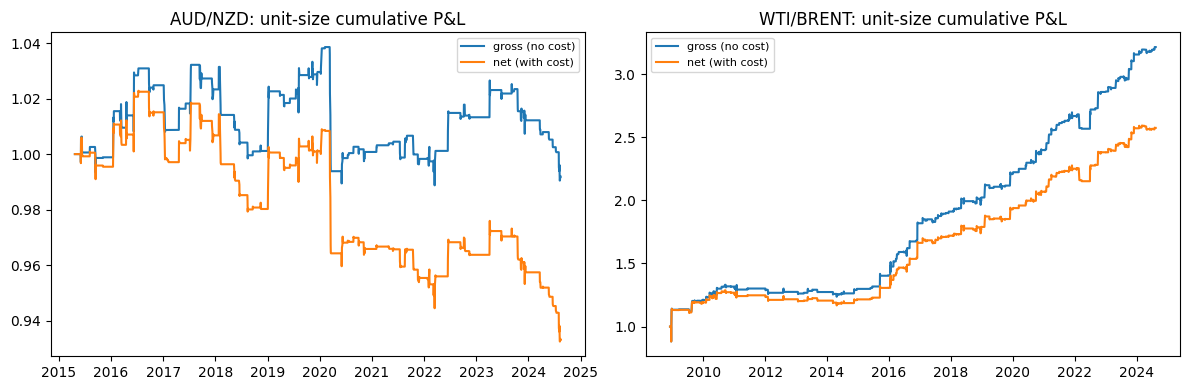

In [3]:
COST_BPS_FX = 2.0     # per leg, per side - FX crosses trade tight
COST_BPS_COMM = 4.0   # per leg, per side - futures: wider bid-ask, exchange fees

def apply_costs(sized_position, sized_beta_leg, cost_bps_per_leg):
    pos_change = sized_position.diff().fillna(sized_position.iloc[0]).abs()
    beta_leg_change = sized_beta_leg.diff().fillna(sized_beta_leg.iloc[0]).abs()
    return cost_bps_per_leg / 1e4 * (pos_change + beta_leg_change)

fx_unit_cost = apply_costs(fx_ep, fx_ep * fx_eb.fillna(0), COST_BPS_FX)
comm_unit_cost = apply_costs(comm_ep, comm_ep * comm_eb.fillna(0), COST_BPS_COMM)

fx_net_unit = fx_raw_ret - fx_unit_cost
comm_net_unit = comm_raw_ret - comm_unit_cost

print(f"AUD/NZD:  net Sharpe (unit size) {sharpe(fx_net_unit):.3f}  |  "
      f"annualised cost drag {fx_unit_cost.mean()*252*1e4:.1f} bps")
print(f"WTI/BRENT: net Sharpe (unit size) {sharpe(comm_net_unit):.3f}  |  "
      f"annualised cost drag {comm_unit_cost.mean()*252*1e4:.1f} bps")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, raw, net, label in [(axes[0], fx_raw_ret, fx_net_unit, "AUD/NZD"), (axes[1], comm_raw_ret, comm_net_unit, "WTI/BRENT")]:
    ax.plot((1 + raw).cumprod(), label="gross (no cost)")
    ax.plot((1 + net).cumprod(), label="net (with cost)")
    ax.set_title(f"{label}: unit-size cumulative P&L")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{DATA_DIR}/05_gross_vs_net_unit.png", dpi=120)
plt.show()

## Sizing: volatility targeting

Each pair targets a fixed 10% annualised vol, scaled by a trailing, causal estimate of the spread's volatility. That trailing vol is computed from the spread's return whether or not a trade is open (`potential_ret` below) - using the strategy's actual realised returns instead dilutes the estimate with all the zero-return flat days and pushes sizing to the cap almost permanently.

In [4]:
TARGET_VOL, VOL_WINDOW, MAX_LEV = 0.10, 60, 3.0

def vol_target_size(df, y_col, x_col, target_vol=TARGET_VOL, window=VOL_WINDOW, max_lev=MAX_LEV, periods=252):
    potential_ret = df[y_col].pct_change() - df["kalman_beta"] * df[x_col].pct_change()
    trailing_vol = potential_ret.rolling(window).std().shift(1) * np.sqrt(periods)
    return (target_vol / trailing_vol).clip(upper=max_lev).fillna(0)

fx_vt_size = vol_target_size(fx_sig, "AUD", "NZD")
comm_vt_size = vol_target_size(comm_sig, "WTI", "BRENT")

print("AUD/NZD vol-target size:", fx_vt_size.describe()[["mean", "std", "min", "max"]].to_dict())
print("WTI/BRENT vol-target size:", comm_vt_size.describe()[["mean", "std", "min", "max"]].to_dict())

AUD/NZD vol-target size: {'mean': 1.964928871804294, 'std': 0.6044450578041631, 'min': 0.0, 'max': 3.0}
WTI/BRENT vol-target size: {'mean': 0.7837661617676137, 'std': 0.33960954350332645, 'min': 0.0, 'max': 1.7316924228463009}


## Sizing: fractional Kelly (comparison)

Kelly fraction from a trailing window of the unit-size strategy's own returns ($f^* = \mu/\sigma^2$), scaled by a 0.5 fractional multiplier - full Kelly assumes the trailing edge estimate is exact, which it never is, and is well known to be too aggressive for a real book. Shown here for comparison; vol targeting is the primary method going forward.

In [5]:
KELLY_WINDOW, KELLY_MULT = 252, 0.5

def kelly_fraction_size(unit_ret, window=KELLY_WINDOW, kelly_mult=KELLY_MULT, max_lev=MAX_LEV, periods=252):
    trailing_mean = unit_ret.rolling(window).mean().shift(1) * periods
    trailing_var = unit_ret.rolling(window).var().shift(1) * periods
    kelly_full = (trailing_mean / trailing_var).clip(lower=0)
    return (kelly_mult * kelly_full).clip(upper=max_lev).fillna(0)

fx_kelly_size = kelly_fraction_size(fx_raw_ret)
comm_kelly_size = kelly_fraction_size(comm_raw_ret)

comparison = pd.DataFrame({
    "AUD/NZD": {
        "unit": sharpe(fx_net_unit),
        "vol_target": sharpe(fx_vt_size * fx_raw_ret - apply_costs(fx_vt_size*fx_ep, fx_vt_size*fx_ep*fx_eb.fillna(0), COST_BPS_FX)),
        "kelly": sharpe(fx_kelly_size * fx_raw_ret - apply_costs(fx_kelly_size*fx_ep, fx_kelly_size*fx_ep*fx_eb.fillna(0), COST_BPS_FX)),
    },
    "WTI/BRENT": {
        "unit": sharpe(comm_net_unit),
        "vol_target": sharpe(comm_vt_size * comm_raw_ret - apply_costs(comm_vt_size*comm_ep, comm_vt_size*comm_ep*comm_eb.fillna(0), COST_BPS_COMM)),
        "kelly": sharpe(comm_kelly_size * comm_raw_ret - apply_costs(comm_kelly_size*comm_ep, comm_kelly_size*comm_ep*comm_eb.fillna(0), COST_BPS_COMM)),
    },
})
print("Net Sharpe by sizing scheme:")
print(comparison)

Net Sharpe by sizing scheme:
             AUD/NZD  WTI/BRENT
unit       -0.374623   0.726903
vol_target -0.510974   0.920637
kelly      -0.478495   0.888632


Going with volatility targeting from here. Kelly's edge estimate is noisy with only ~80-140 trades per pair - it floors to zero fairly often after a losing trailing window - and vol targeting is the more standard, less estimation-sensitive choice on a real desk.

## Full pipeline: costs + vol-target sizing

In [6]:
def build_pair_backtest(df, y_col, x_col, cost_bps_per_leg, target_vol=TARGET_VOL,
                         vol_window=VOL_WINDOW, max_lev=MAX_LEV, periods=252):
    ep, eb = build_executed_position_and_beta(df)
    raw_ret = (ep * (df[y_col].pct_change() - eb * df[x_col].pct_change())).fillna(0.0)
    size = vol_target_size(df, y_col, x_col, target_vol, vol_window, max_lev, periods)

    sized_position = size * ep
    sized_beta_leg = sized_position * eb.fillna(0)
    cost = apply_costs(sized_position, sized_beta_leg, cost_bps_per_leg)
    net_return = size * raw_ret - cost

    return pd.DataFrame({
        "unit_position": ep, "size": size, "sized_position": sized_position,
        "raw_return": raw_ret, "cost": cost, "net_return": net_return,
    })

fx_bt = build_pair_backtest(fx_sig, "AUD", "NZD", COST_BPS_FX)
comm_bt = build_pair_backtest(comm_sig, "WTI", "BRENT", COST_BPS_COMM)

## Portfolio combination and exposure cap

Equal 50/50 notional split across the two sleeves - a simple, explicit choice rather than risk parity or an optimised weighting (a reasonable extension later). A daily gross exposure cap (2.0x combined capital) scales both sleeves down proportionally on the rare day both are highly levered at once, as a backstop against the two independently-sized sleeves stacking into more combined risk than intended.

In [7]:
WEIGHT_FX, WEIGHT_COMM, GROSS_CAP = 0.5, 0.5, 2.0

combined = pd.DataFrame(index=fx_bt.index.union(comm_bt.index)).sort_index()
combined["fx_sized_position"] = fx_bt["sized_position"].reindex(combined.index).fillna(0)
combined["comm_sized_position"] = comm_bt["sized_position"].reindex(combined.index).fillna(0)
combined["fx_net_return"] = fx_bt["net_return"].reindex(combined.index).fillna(0)
combined["comm_net_return"] = comm_bt["net_return"].reindex(combined.index).fillna(0)

gross_exposure = WEIGHT_FX * combined["fx_sized_position"].abs() + WEIGHT_COMM * combined["comm_sized_position"].abs()
scale = (GROSS_CAP / gross_exposure.replace(0, np.nan)).clip(upper=1.0).fillna(1.0)

combined["gross_exposure"] = gross_exposure
combined["scale"] = scale
combined["portfolio_return"] = scale * (WEIGHT_FX * combined["fx_net_return"] + WEIGHT_COMM * combined["comm_net_return"])

n_bind = (gross_exposure > GROSS_CAP).sum()
print(f"Gross exposure cap binds on {n_bind} / {len(combined)} days ({100*n_bind/len(combined):.2f}%) - "
      "rarely active, since each sleeve's own 3x per-pair cap already limits worst-case combined exposure to 3.0x.")

Gross exposure cap binds on 3 / 3983 days (0.08%) - rarely active, since each sleeve's own 3x per-pair cap already limits worst-case combined exposure to 3.0x.


## Performance metrics

In [8]:
def trade_level_stats(unit_position, net_return):
    episode_id = (unit_position != unit_position.shift(1)).cumsum()
    trades = []
    for _, grp_pos in unit_position.groupby(episode_id):
        if grp_pos.iloc[0] == 0:
            continue
        idx = grp_pos.index
        trades.append({"n_days": len(idx), "pnl": net_return.loc[idx].sum()})
    trades_df = pd.DataFrame(trades)
    if trades_df.empty:
        return np.nan, np.nan, 0
    return (trades_df["pnl"] > 0).mean(), trades_df["n_days"].mean(), len(trades_df)

def full_metrics(ret, sized_position=None, unit_position=None, periods=252):
    ret = ret.dropna()
    m = {}
    m["annual_return"] = (1 + ret).prod() ** (periods / len(ret)) - 1
    m["sharpe"] = sharpe(ret, periods)
    downside = ret[ret < 0]
    m["sortino"] = ret.mean() / downside.std() * np.sqrt(periods) if len(downside) and downside.std() > 0 else np.nan
    cum = (1 + ret).cumprod()
    m["max_drawdown"] = (cum / cum.cummax() - 1).min()
    if sized_position is not None:
        m["annual_turnover"] = sized_position.diff().abs().sum() / (len(sized_position) / periods)
    if unit_position is not None:
        hit_rate, avg_hold, n_trades = trade_level_stats(unit_position, ret)
        m["hit_rate"], m["avg_holding_days"], m["n_trades"] = hit_rate, avg_hold, n_trades
    return m

results = pd.DataFrame({
    "AUD/NZD": full_metrics(fx_bt["net_return"], fx_bt["sized_position"], fx_bt["unit_position"]),
    "WTI/BRENT": full_metrics(comm_bt["net_return"], comm_bt["sized_position"], comm_bt["unit_position"]),
    "Portfolio (50/50)": full_metrics(combined["portfolio_return"]),
}).T
print(results)

                   annual_return    sharpe   sortino  max_drawdown  \
AUD/NZD                -0.019222 -0.510974 -0.260848     -0.196764   
WTI/BRENT               0.042444  0.920637  0.731754     -0.078386   
Portfolio (50/50)       0.014879  0.564767  0.468422     -0.045588   

                   annual_turnover  hit_rate  avg_holding_days  n_trades  
AUD/NZD                  36.184956  0.500000          2.892857      84.0  
WTI/BRENT                16.661448  0.702899          2.934783     138.0  
Portfolio (50/50)              NaN       NaN               NaN       NaN  


AUD/NZD is a net loser after realistic costs - negative Sharpe and annual return, despite passing the notebook 01 cointegration tests within its post-2014 regime. G10 FX crosses are an extremely efficient, heavily-arbitraged market, and a daily-frequency mean-reversion signal doesn't clear realistic costs here. That's a real, useful negative result, not a bug.

WTI/Brent is net positive - Sharpe 0.92, modest but real annual return, contained drawdown. A structurally-linked commodity spread with a physical-arbitrage floor seems to retain more edge than a purely statistical FX relationship.

The blended portfolio has a noticeably smaller max drawdown than either sleeve alone - a genuine diversification benefit even though AUD/NZD drags on blended return.

Holding periods are short (median ~2 days), which follows from how strongly mean-reverting the Kalman spread already is. Makes the strategy turnover- and cost-sensitive; a wider entry/exit band would trade fewer, larger trades against more frequent smaller ones - worth trying as an extension.

## Cumulative portfolio P&L

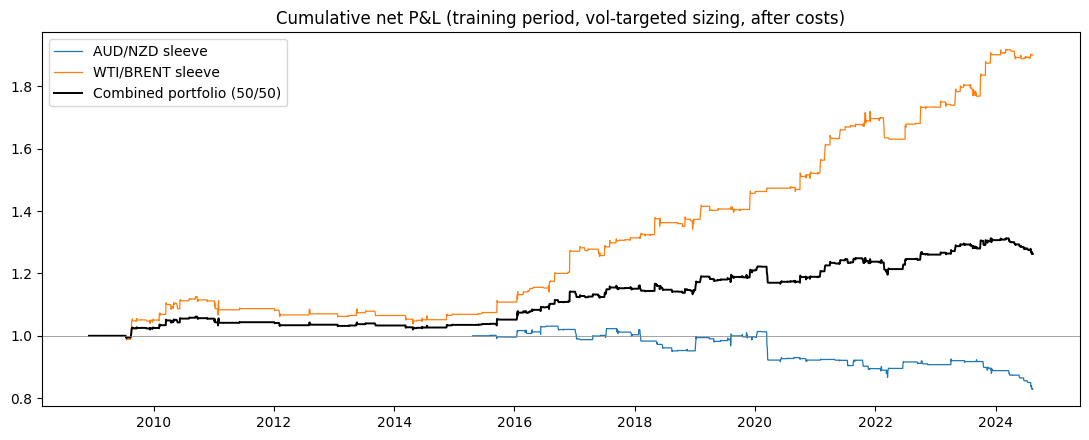

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot((1 + fx_bt["net_return"]).cumprod(), label="AUD/NZD sleeve", linewidth=0.9)
ax.plot((1 + comm_bt["net_return"]).cumprod(), label="WTI/BRENT sleeve", linewidth=0.9)
ax.plot((1 + combined["portfolio_return"]).cumprod(), label="Combined portfolio (50/50)", linewidth=1.4, color="black")
ax.axhline(1, color="grey", linewidth=0.5)
ax.set_title("Cumulative net P&L (training period, vol-targeted sizing, after costs)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{DATA_DIR}/05_cumulative_pnl.png", dpi=120)
plt.show()

## Save

In [10]:
out = pd.DataFrame({
    "fx_net_return": combined["fx_net_return"], "comm_net_return": combined["comm_net_return"],
    "fx_sized_position": combined["fx_sized_position"], "comm_sized_position": combined["comm_sized_position"],
    "gross_exposure": combined["gross_exposure"], "scale": combined["scale"],
    "portfolio_return": combined["portfolio_return"],
})
out.to_parquet(f"{DATA_DIR}/backtest_results.parquet")

backtest_config = {
    "cost_bps_fx": COST_BPS_FX, "cost_bps_comm": COST_BPS_COMM,
    "target_vol": TARGET_VOL, "vol_window": VOL_WINDOW, "max_leverage": MAX_LEV,
    "kelly_window": KELLY_WINDOW, "kelly_mult": KELLY_MULT,
    "weight_fx": WEIGHT_FX, "weight_comm": WEIGHT_COMM, "gross_cap": GROSS_CAP,
    "sizing_method_used": "vol_target",
}
with open(f"{DATA_DIR}/backtest_config.json", "w") as f:
    json.dump(backtest_config, f, indent=2)

results.to_csv(f"{DATA_DIR}/backtest_metrics_train.csv")
print("Saved backtest_results.parquet, backtest_config.json, backtest_metrics_train.csv to", DATA_DIR)

Saved backtest_results.parquet, backtest_config.json, backtest_metrics_train.csv to ../data


Notebook 06 runs the ablations (Kalman vs rolling-OLS hedge, HMM on/off, cost sensitivity) and the final holdout evaluation - the first and only time the 2024-08-15+ data gets touched.